# Material de aula - FACENS - Aprendizado de Máquina


## Particle Swarm Optimization - Laboratório 04

In [1]:
#CÉLULA PSO-LIB-01
import numpy as np
import math
import matplotlib.pyplot as plt
from enum import Enum
from operator import xor
%matplotlib inline

In [2]:
#CÉLULA PSO-LIB-02
# Função para cálculo de fitness (aptidão de cada individuo)
def fitness(individual) :  
    
    #(x, y) = scale(individual)
    
    x = individual[0]
    y = individual[1]
    
    num = (np.sin(np.sqrt(x**2+y**2)))**2 - 0.5
    den = (1 + 0.001*(x**2+y**2)) ** 2
    z = 0.5 - (num / den)

    return z


In [14]:
#CÉLULA PSO-LIB-03
def plot_population(P, generation):
    
    xmin =-100
    xmax = 100
    ymin =-100
    ymax = 100
    
    xAxis = []
    yAxis = []
    for individual in P : #pega os individuos na população        
        x = individual['X']
        y = individual['Y']
        
        xAxis.append(x)
        yAxis.append(y)
    
    plt.figure()
    plt.plot(xAxis, yAxis, 'bo')
    plt.axis([xmin, xmax, ymin, ymax])
    
    plt.xlabel('x')
    plt.ylabel('y')
    sTitle = ('Populacao na geração {}'.format(generation))
    plt.title(sTitle)
    plt.grid()

In [4]:
#CÉLULA PSO-LIB-05
def calcAllPBest(vParticles) :
    vParticlesRet = []
    
    for particle in vParticles :
        x = particle['X']
        y = particle['Y']
        xBest = particle['XBest']
        yBest = particle['YBest']
        if (fitness((x,y)) >= fitness((xBest, yBest)) ) :
            particle['XBest'] = x
            particle['YBest'] = y
            
        vParticlesRet.append(particle)
    
    return vParticlesRet

In [5]:
#CÉLULA PSO-LIB-06
# Verifica o gbest
def calcGBest(vParticles) :
    #Inicializa variavel
    calcAllPBest(vParticles)
    x = vParticles[0]['XBest']
    y = vParticles[0]['YBest']
    maxFitness = fitness((x,y))

    for particle in vParticles :
        x = particle['XBest']
        y = particle['YBest']
        currentFitness = fitness((x,y))
        if ( currentFitness >= maxFitness ) :
            maxFitness = currentFitness
            gBest = {'X' : x, 'Y' : y, 'Fitness' : maxFitness}
    
    return gBest

In [6]:
#CÉLULA PSO-LIB-07
def calcPBest(particle) :   
    x = particle['X']
    y = particle['Y']
    xBest = particle['XBest']
    yBest = particle['YBest']
    currentFitness = fitness((x,y))
    if (currentFitness >= fitness((xBest, yBest)) ) :
        xBest = x
        yBest = y
                
    return (xBest, yBest)

# PSO - inicio

# 1 - Criando o enxame de partículas

Utilizando Jupyter e NumPy: escreva a função que cria um enxame de partículas inicial com valores aleatórios no domínio do espaço de busca.

Domínio da função: 
- xmin = -100
- xmax =  100
- ymin = -100
- xmax =  100

In [10]:
#CÉLULA PSO-MAIN-01
#Parâmetros
size_pop   = 100
max_generations = 100
stop_condition = 0.95

#Limites do dominio de definição
x_min = -100
x_max =  100

y_min = -100
y_max =  100


# Cada particula tem dados (X,Y, XBest, YBest)
gBest = {'X' : 0, 'Y' : 0, 'Fitness' : 0}
vParticles = []

deltaT = 1
c1 = 0.2
c2 = 0.3
w  = 0.2

vMax = 500 #limitação de velocidade

#r1 e r2 deverão ser extraídas de uma distribuição uniforme e são atualizadas a cada cálculo de velocidade da população
#as melhores posições, individual e global, são obtidas através da função de fitness

In [11]:
#CÉLULA PSO-MAIN-02
#Inicializando população
vParticles=[]

for i in range(0, size_pop):
    x   =  x_min + np.random.random() * (x_max - x_min)
    y   =  y_min + np.random.random() * (y_max - y_min)
    vx  = (x_min + np.random.random() * (x_max - x_min)) / deltaT
    vy  = (y_min + np.random.random() * (y_max - y_min)) / deltaT
    vParticles.append({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })
    
#Calcula pBest
#vParticles = calcPBest(vParticles)

#Calcula gbest
gBest = calcGBest(vParticles)
        

[{'X': 30.630027830073317, 'Y': -70.7177559053278, 'XBest': 30.630027830073317, 'YBest': -70.7177559053278, 'VX': 51.020918759246854, 'VY': 97.45082391209641}, {'X': 91.95570593326764, 'Y': 35.25023200464338, 'XBest': 91.95570593326764, 'YBest': 35.25023200464338, 'VX': -34.67084087592305, 'VY': -96.78692896007657}, {'X': 23.620939772990283, 'Y': 17.26303955017798, 'XBest': 23.620939772990283, 'YBest': 17.26303955017798, 'VX': 9.509692300098521, 'VY': 74.78519533252918}, {'X': -2.0838346048417122, 'Y': -22.93563153880909, 'XBest': -2.0838346048417122, 'YBest': -22.93563153880909, 'VX': -43.05248151673757, 'VY': 65.52033504814659}, {'X': 64.59088393334955, 'Y': 36.458739496967155, 'XBest': 64.59088393334955, 'YBest': 36.458739496967155, 'VX': -20.334423965607073, 'VY': -13.334011106963345}, {'X': 57.39095191927515, 'Y': -4.838941353832311, 'XBest': 57.39095191927515, 'YBest': -4.838941353832311, 'VX': -79.5394444916177, 'VY': 94.99039352577992}, {'X': -64.21902332427831, 'Y': 98.8866402

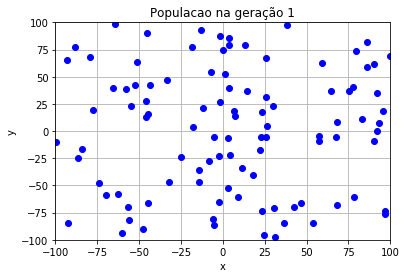

In [12]:
#Teste
plot_population(vParticles, 1)
print(vParticles)

## Validação

plot_population(vParticles, 1)        

print(vParticles)

## Observe a disposição das particulas no dominio. Use populações menores e verifique se todas estão presentes.